## Import modules

In [1]:
import numpy as np
import tifffile
import matplotlib.pyplot as plt
import glob
import rasterio

In [2]:
import os
path_export = '../../data/InSAR_results/'
if not os.path.exists(path_export):
    os.makedirs(path_export)

### Set Terra-X wavelength 

In [3]:
wavelength = 0.031067

### Import imagery

In [12]:
path = './InW*/**/*.tif'
files = glob.glob(path, recursive=True)
n = 2
image = tifffile.imread(files[n], key=0)
filename = files[n].split('/')[-1]
print(f"Loaded image: {filename} with shape {image.shape}")

Loaded image: InW_IMO_20250323_20250403_TAR6.tif with shape (3744, 3059)


## Processing

### Seperate imaginary and real parts

In [13]:
im = np.sin(image)
real = np.cos(image)

### Plots

Text(0.5, 1.0, 'Imaginary Part (sine)')

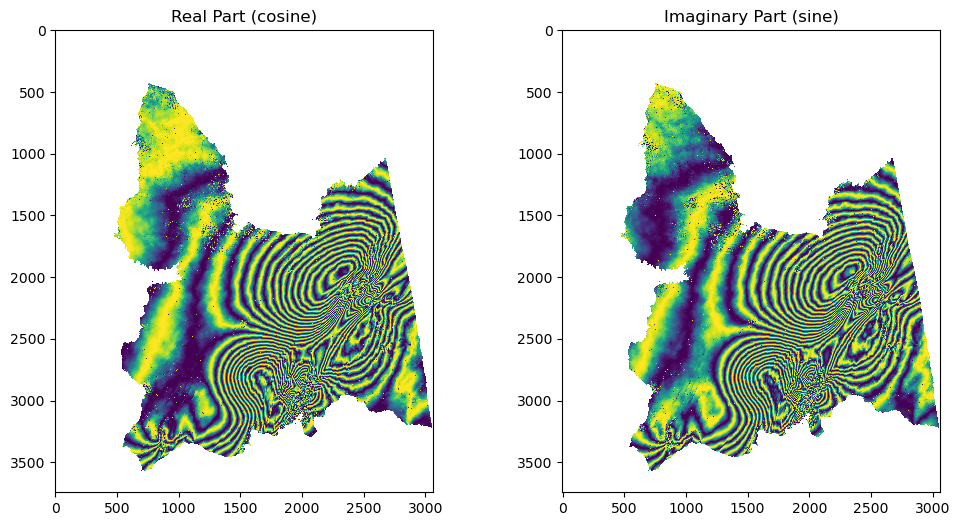

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(real, interpolation='none')
ax[0].set_title('Real Part (cosine)')
ax[1].imshow(im, interpolation='none')
ax[1].set_title('Imaginary Part (sine)')

### Calculating gradient

In [15]:
gradient_ns_b = np.zeros((im.shape[0], im.shape[1]), dtype=np.float32)
gradient_ew_b = np.zeros((im.shape[0], im.shape[1]), dtype=np.float32)
for i, line in enumerate(zip(real, im)):
    if i == 0:
        continue
    gradient_ns_b[i] = line[0] * (line[1] - im[i-1]) - line[1] * (line[0] - real[i-1])/(line[0]**2 + line[1]**2)
for j, line in enumerate(zip(real.T, im.T)):
    if j == 0:
        continue
    gradient_ew_b[:,j] = line[0] * (line[1] - im[:,j-1]) - line[1] * (line[0] - real[:,j-1])/(line[0]**2 + line[1]**2)


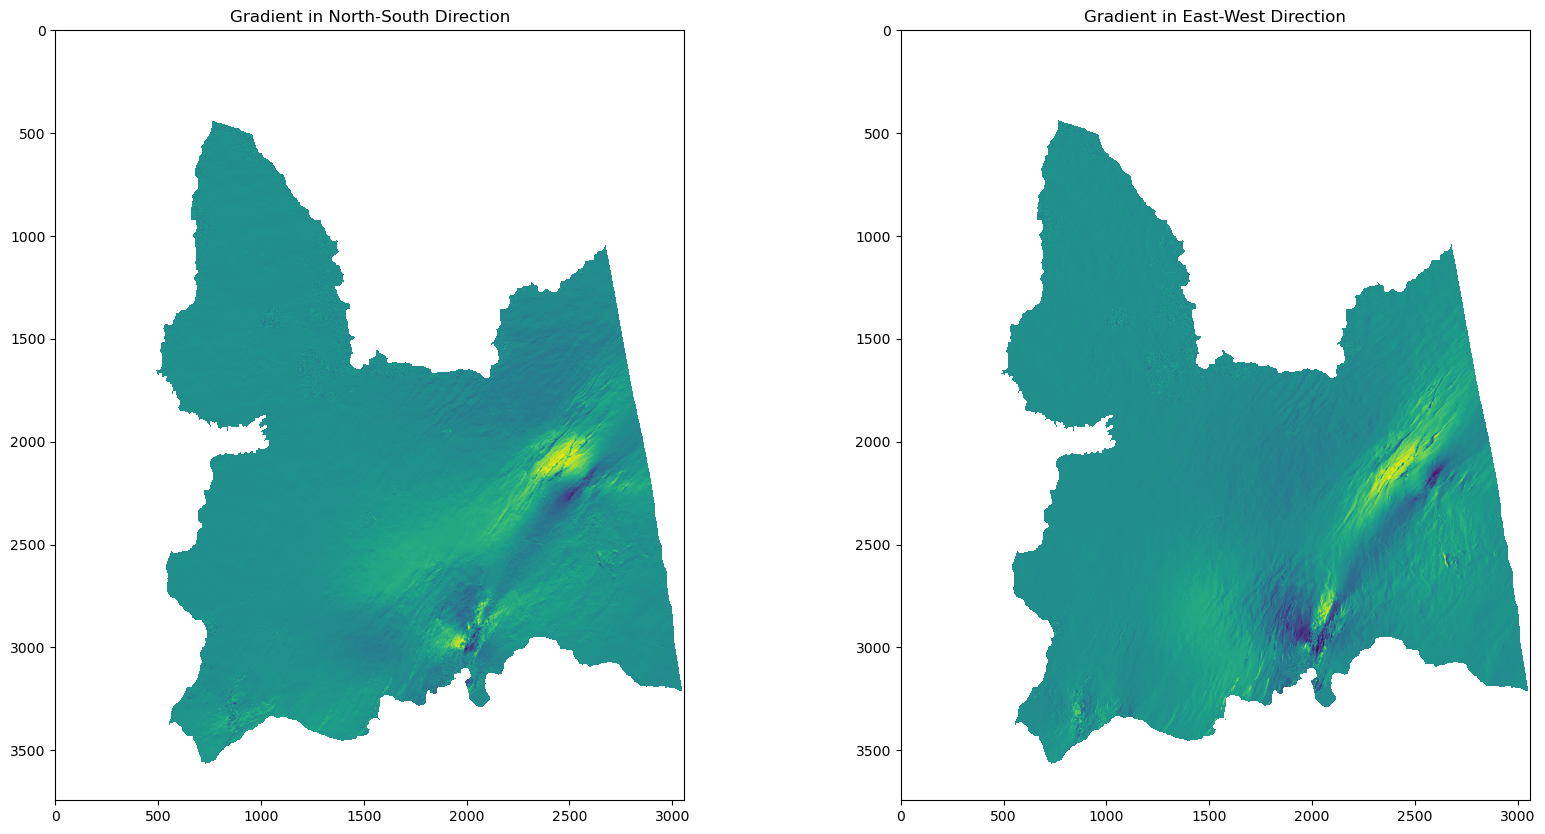

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(20, 10))
ax[0].imshow(gradient_ns_b, cmap='viridis')
ax[0].set_title('Gradient in North-South Direction')
ax[1].imshow(gradient_ew_b, cmap='viridis')
ax[1].set_title('Gradient in East-West Direction')
plt.show()

In [17]:
strain_ns = wavelength/(4 * np.pi) * gradient_ns_b * 1/10.8
strain_ew = wavelength/(4 * np.pi) * gradient_ew_b * 1/10

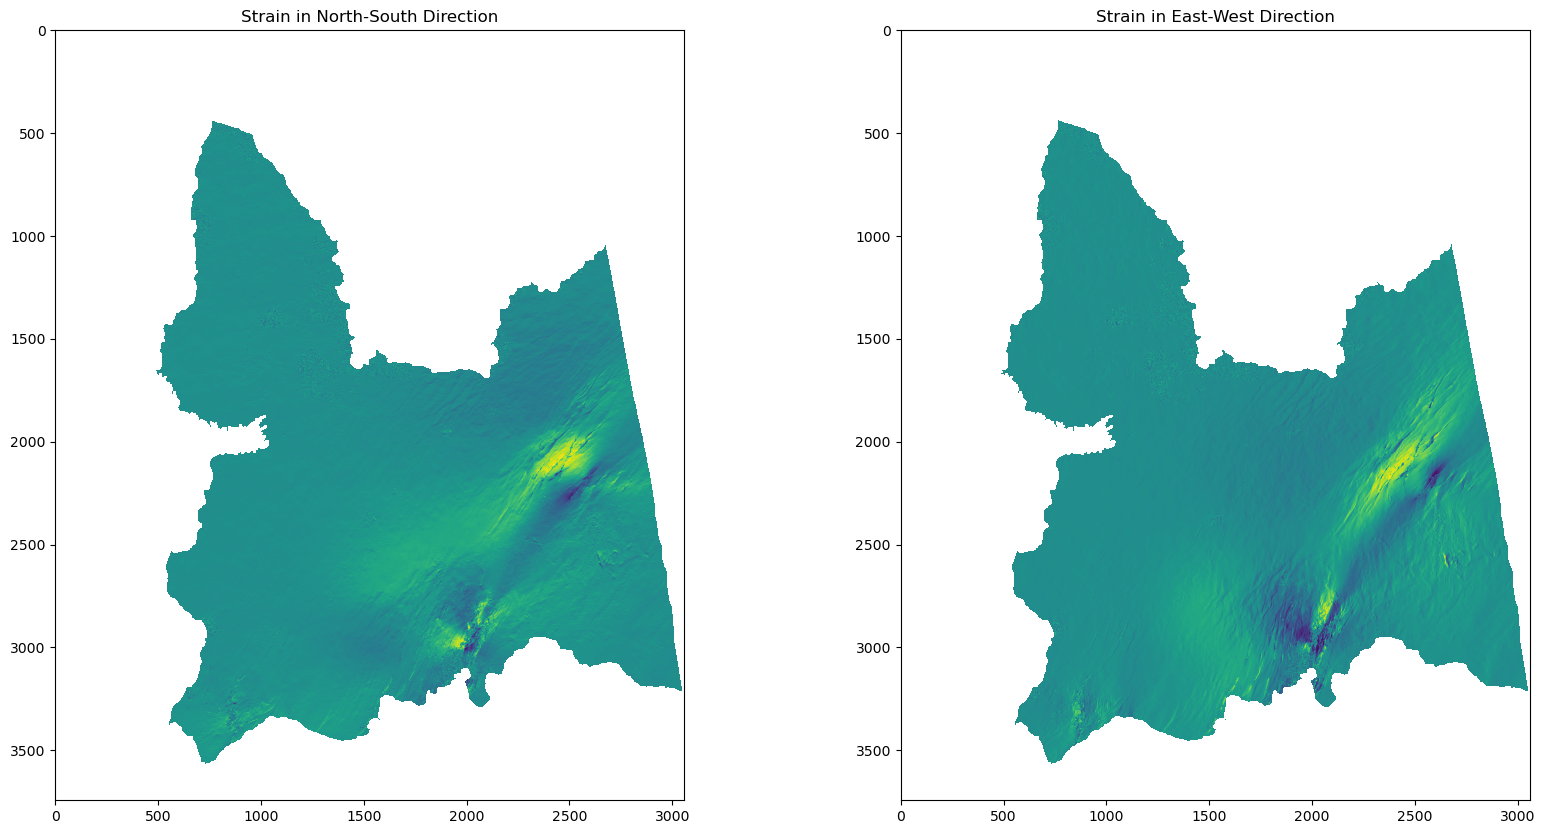

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(20, 10))
ax[0].imshow(strain_ns, cmap='viridis')
ax[0].set_title('Strain in North-South Direction')
ax[1].imshow(strain_ew, cmap='viridis')
ax[1].set_title('Strain in East-West Direction')
plt.show()

### Exporting the results

In [19]:
# Open the TIFF file
with rasterio.open(files[n]) as img:
    data = img.read()
    profile = img.profile
    profile.update(dtype=rasterio.float32, count=1)
    with rasterio.open(path_export + 'strain_azimuth_%s_NS.tif'%filename, 'w', **profile) as dst:
        dst.write(strain_ns, 1)
    with rasterio.open(path_export + 'strain_azimuth_%s_EW.tif'%filename, 'w', **profile) as dst:
        dst.write(strain_ew, 1)